# DS1 k-nearest neighbours (kNN)

Classifies DS1 patients as CKD or not CKD by looking at the k most similar training patients. The only input is the preprocessed train/test split from `Data_Preprocessing.ipynb` (`3_preprocessed_data/`), found through `configs/config.json`. Every choice is made with cross-validation on the training set; the test set is used once, at the end.

| Step | What it does |
|---|---|
| 1 | Load the preprocessed data |
| 2 | Baseline kNN with k = 5 |
| 3 | Tune k, weights and distance |
| 4 | Let kNN pick its own features |
| 5 | Add the hierarchical clusters |
| 6 | Check the scores are stable |
| 7 | Look at the errors on the training folds |
| 8 | Evaluate the final model on the test set |
| 9 | Compare all versions |

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import AgglomerativeClustering
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import GridSearchCV, StratifiedKFold, RepeatedStratifiedKFold, cross_val_score, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

root = Path.cwd()
while not (root / "configs" / "config.json").is_file():
    root = root.parent

config = json.loads((root / "configs" / "config.json").read_text())
ds = config["datasets"]["list"]["DS1"]
base = (root / "configs" / config["paths"]["datasets_dir"] / ds["folder"]).resolve()
target = ds["target"]["column"]
class_order = ds["target"]["values"]
RANDOM_STATE = config["training"]["random_state"]

## 1. Load the preprocessed data

We load the preprocessed train and test sets with all 30 features. kNN compares patients by distance, so it needs data with no missing values and features on the same scale, which preprocessing already provides. File paths come from the config, and labels are mapped to 0/1 in the config order (ckd = 0, notckd = 1).

In [2]:
train = pd.read_csv(base / ds["files"]["preprocessed"]["train"])
test = pd.read_csv(base / ds["files"]["preprocessed"]["test"])

X_train, X_test = train.drop(columns=[target]), test.drop(columns=[target])
y_train = train[target].map({c: i for i, c in enumerate(class_order)})
y_test = test[target].map({c: i for i, c in enumerate(class_order)})

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Training classes:", train[target].value_counts().to_dict())

Train: (320, 30) Test: (80, 30)
Training classes: {'ckd': 200, 'notckd': 120}


**Observation:**
- 320 training and 80 test patients with 30 features, all scaled and with no missing values
- Classes are 200 CKD vs 120 not CKD, so macro F1 is used throughout, as it weights both classes equally

## 2. Baseline: k = 5

We first train kNN with the default k = 5 on all 30 features, to get a starting score and see whether the later steps help. It is scored with 5-fold stratified cross-validation on the training set, using macro F1, which weights both classes equally.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
base_cv = cross_val_score(KNeighborsClassifier(n_neighbors=5), X_train, y_train, cv=cv, scoring="f1_macro")
print(f"Baseline 5-fold macro F1: {base_cv.mean():.3f} (std {base_cv.std():.3f})")

Baseline 5-fold macro F1: 0.977 (std 0.017)


**Observation:**
- With the default k = 5, kNN already reaches a 5-fold macro F1 of 0.977 (std 0.017)
- The classes separate well, so the later steps can only add a little

## 3. Tune k, weights and distance

kNN results depend strongly on how many neighbours vote, how their votes are weighted and how distance is measured. We try all 52 combinations below with the same 5 folds and keep the one with the best mean macro F1.

| Setting | Values | Meaning |
|---|---|---|
| k (`n_neighbors`) | 1 to 25, odd only | How many neighbours vote; odd avoids ties between 2 classes |
| `weights` | uniform, distance | Every neighbour votes the same, or closer neighbours count more |
| `p` | 1, 2 | Manhattan or Euclidean distance |

Best settings: {'n_neighbors': 3, 'p': 2, 'weights': 'uniform'}
Best 5-fold macro F1: 0.980 (std 0.016)


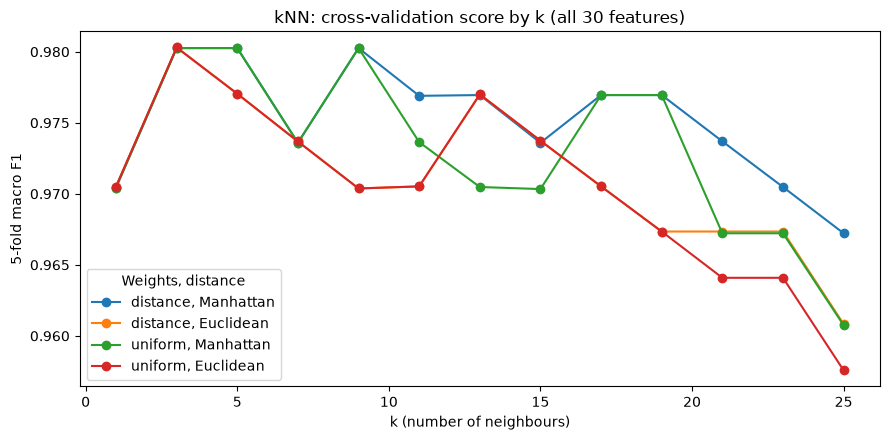

In [4]:
grid = {"n_neighbors": list(range(1, 26, 2)), "weights": ["uniform", "distance"], "p": [1, 2]}
search = GridSearchCV(KNeighborsClassifier(), grid, cv=cv, scoring="f1_macro").fit(X_train, y_train)
print("Best settings:", search.best_params_)
print(f"Best 5-fold macro F1: {search.best_score_:.3f} (std {search.cv_results_['std_test_score'][search.best_index_]:.3f})")

res = pd.DataFrame(search.cv_results_)
fig, ax = plt.subplots(figsize=(9, 4.5))
for (w, p), part in res.groupby(["param_weights", "param_p"]):
    ax.plot(part["param_n_neighbors"], part["mean_test_score"], marker="o", label=f"{w}, {'Manhattan' if p == 1 else 'Euclidean'}")
ax.set(xlabel="k (number of neighbours)", ylabel="5-fold macro F1", title="kNN: cross-validation score by k (all 30 features)")
ax.legend(title="Weights, distance")
fig.tight_layout()
plt.show()

**Observation:**
- Best: k = 3, Euclidean distance, equal votes (5-fold macro F1 0.980), only slightly above the baseline
- Every setting scores between 0.958 and 0.980, so with all 30 features the settings matter little
- Scores drop slowly as k grows, as more distant and less similar patients get a vote

## 4. Let kNN pick its own features

kNN uses every feature in the distance, so features that do not help add noise and can pull patients towards the wrong neighbours. Here kNN keeps only the features that best separate CKD from not CKD, ranked with the ANOVA F-test (`SelectKBest`). The ranking is learned inside each fold on the training part only, and the number of features (5 to all) is tuned together with the kNN settings.

Best settings: {'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'distance', 'select__k': 15}
Best 5-fold macro F1: 0.997 (std 0.007)
15 features kept: ['sc', 'urea_creatinine_ratio', 'bu_sc_interaction', 'sg', 'al', 'sod', 'hemo', 'pcv', 'rbcc', 'comorbidity_count', 'log_sc', 'urine_abnormality_score', 'htn', 'dm', 'appet']


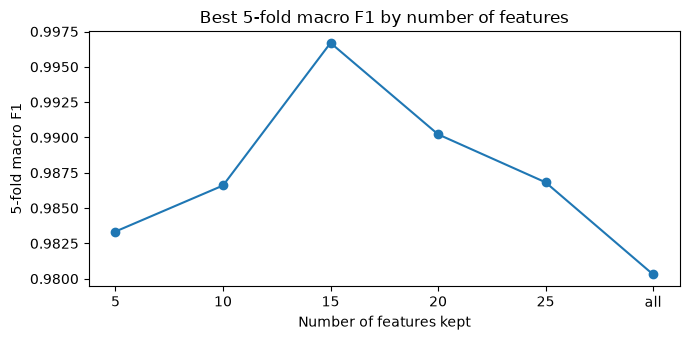

In [5]:
feature_counts = [5, 10, 15, 20, 25, "all"]
pipe_sel = Pipeline([("select", SelectKBest(f_classif)), ("knn", KNeighborsClassifier())])
grid_sel = {"select__k": feature_counts, **{f"knn__{k}": v for k, v in grid.items()}}
search_sel = GridSearchCV(pipe_sel, grid_sel, cv=cv, scoring="f1_macro").fit(X_train, y_train)
print("Best settings:", search_sel.best_params_)
print(f"Best 5-fold macro F1: {search_sel.best_score_:.3f} (std {search_sel.cv_results_['std_test_score'][search_sel.best_index_]:.3f})")

chosen = X_train.columns[search_sel.best_estimator_["select"].get_support()].tolist()
print(f"{len(chosen)} features kept:", chosen)

by_count = pd.DataFrame(search_sel.cv_results_).groupby("param_select__k", sort=False)["mean_test_score"].max()
by_count.index = by_count.index.astype(str)
by_count.plot(marker="o", figsize=(7, 3.5), title="Best 5-fold macro F1 by number of features")
plt.xlabel("Number of features kept")
plt.ylabel("5-fold macro F1")
plt.tight_layout()
plt.show()

**Observation:**
- Keeping 15 features works best (5-fold macro F1 0.997, std 0.007), with k = 5, Manhattan distance and closer neighbours counting more
- Kept: kidney markers (creatinine and its engineered versions, specific gravity, albumin), blood markers (hemoglobin, packed cell volume, red cell count, sodium), the comorbidity and urine scores, and hypertension, diabetes and appetite
- Every feature count from 5 to 25 beats all 30 features (0.980), so dropping unhelpful features helps kNN more than tuning does

## 5. Add the hierarchical clusters

`Clustering.ipynb` found that hierarchical clustering (Ward, 2 clusters) almost matches the diagnosis without seeing it (Adjusted Rand index 0.87), so the cluster might help kNN. We add it as one extra 0/1 feature and repeat step 4. The clusters are found inside each fold on the training part only, using all 30 features as in `Clustering.ipynb`, and every patient gets the label of the nearest cluster centre. The feature ranking then decides whether the cluster is kept.

In [6]:
class AddCluster(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        labels = AgglomerativeClustering(2, linkage="ward").fit_predict(X)
        self.centres_ = X.groupby(labels).mean()
        return self

    def transform(self, X):
        dist = ((X.values[:, None, :] - self.centres_.values[None, :, :]) ** 2).sum(axis=2)
        return X.assign(cluster=dist.argmin(axis=1))


pipe_clu = Pipeline([("cluster", AddCluster()), ("select", SelectKBest(f_classif)), ("knn", KNeighborsClassifier())])
search_clu = GridSearchCV(pipe_clu, grid_sel, cv=cv, scoring="f1_macro").fit(X_train, y_train)
print("Best settings:", search_clu.best_params_)
print(f"Best 5-fold macro F1: {search_clu.best_score_:.3f} (std {search_clu.cv_results_['std_test_score'][search_clu.best_index_]:.3f})")

kept = search_clu.best_estimator_["select"].get_feature_names_out().tolist()
print("Cluster kept by the feature ranking:", "cluster" in kept)

Best settings: {'knn__n_neighbors': 9, 'knn__p': 2, 'knn__weights': 'uniform', 'select__k': 15}
Best 5-fold macro F1: 0.993 (std 0.013)
Cluster kept by the feature ranking: True


**Observation:**
- The feature ranking keeps the cluster among the 15 features, so it does separate the classes
- But the score is a little lower than without it (0.993 vs 0.997), as the cluster mostly repeats what the kidney and blood markers already show

## 6. Check the scores are stable

Steps 3 to 5 each picked their best out of many settings on the same 5 folds, so their scores are a little optimistic. To compare them fairly, we score the best version of each again with 10 different 5-fold splits (50 scores per version). The version with the highest mean becomes the final model.

,Mean macro F1,Std
"Tuned, all features",0.976,0.021
"Tuned, own feature selection",0.993,0.012
"Tuned, selection + cluster",0.988,0.014


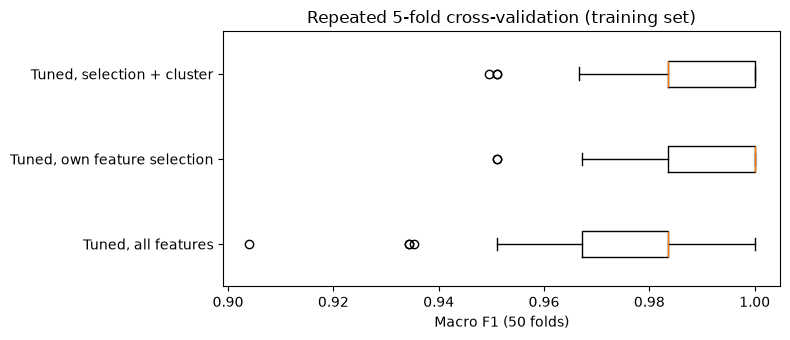

Final model: Tuned, own feature selection


In [7]:
candidates = {
    "Tuned, all features": search.best_estimator_,
    "Tuned, own feature selection": search_sel.best_estimator_,
    "Tuned, selection + cluster": search_clu.best_estimator_,
}
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
repeated = {name: cross_val_score(model, X_train, y_train, cv=rcv, scoring="f1_macro") for name, model in candidates.items()}
display(pd.DataFrame({"Mean macro F1": {n: s.mean() for n, s in repeated.items()},
                      "Std": {n: s.std() for n, s in repeated.items()}}).round(3))

plt.figure(figsize=(8, 3.5))
plt.boxplot(list(repeated.values()), tick_labels=list(repeated), orientation="horizontal")
plt.xlabel("Macro F1 (50 folds)")
plt.title("Repeated 5-fold cross-validation (training set)")
plt.tight_layout()
plt.show()

final_name = max(repeated, key=lambda n: repeated[n].mean())
final = candidates[final_name]
print("Final model:", final_name)

**Observation:**
- Repeated cross-validation keeps the same order: own feature selection 0.993, selection + cluster 0.988, all features 0.976
- Own feature selection also has the smallest spread (std 0.012), so it is the final model
- Scores are a little lower than in steps 3 to 5, as expected once the settings are tested on fresh splits

## 7. Look at the errors on the training folds

The test set is small, so we also look at the 320 out-of-fold predictions on the training set to see where kNN fails. For each error, we show the CKD probability and the patient's hierarchical cluster.

In [8]:
p_ckd = cross_val_predict(final, X_train, y_train, cv=cv, method="predict_proba")[:, 0]
oof_pred = np.where(p_ckd >= 0.5, 0, 1)
errors = np.where(oof_pred != y_train.values)[0]
print(f"Out-of-fold errors: {len(errors)} of {len(y_train)}")

train_cluster = AddCluster().fit(X_train).transform(X_train)["cluster"]
display(pd.DataFrame({
    "True class": train[target].iloc[errors].values,
    "CKD probability": p_ckd[errors].round(2),
    "Cluster": train_cluster.iloc[errors].values,
    "CKD share of that cluster": [round((y_train[train_cluster == c] == 0).mean(), 2) for c in train_cluster.iloc[errors]],
}, index=errors).rename_axis("Training row"))

Out-of-fold errors: 1 of 320


,True class,CKD probability,Cluster,CKD share of that cluster
Training row,,,,
183,ckd,0.38,1,0.22


**Observation:**
- The final model gets 319 of 320 training patients right when they are held out
- The one error is a CKD patient predicted as not CKD with a CKD probability of 0.38, so the vote was close
- This patient is in hierarchical cluster 1, where only 22% of patients have CKD, so clustering also groups them with the healthy patients

## 8. Evaluate the final model on the test set

The final model is tested once on the 80 test patients. The test set played no part in any choice, so this is a fair estimate for new patients. We report accuracy, macro F1, ROC AUC (how well the CKD probability ranks patients), per-class precision and recall, and the confusion matrix.

Accuracy: 1.000
Macro F1: 1.000
ROC AUC:  1.000

              precision    recall  f1-score   support

         ckd      1.000     1.000     1.000        50
      notckd      1.000     1.000     1.000        30

    accuracy                          1.000        80
   macro avg      1.000     1.000     1.000        80
weighted avg      1.000     1.000     1.000        80



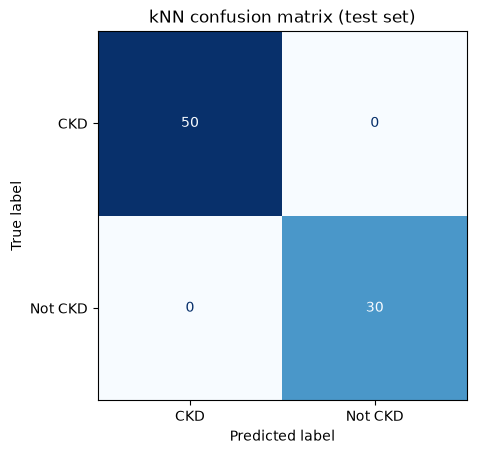

In [9]:
y_pred = final.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"Macro F1: {f1_score(y_test, y_pred, average='macro'):.3f}")
print(f"ROC AUC:  {roc_auc_score(y_test == 0, final.predict_proba(X_test)[:, 0]):.3f}")
print()
print(classification_report(y_test, y_pred, target_names=class_order, digits=3))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["CKD", "Not CKD"]).plot(cmap="Blues", colorbar=False)
plt.title("kNN confusion matrix (test set)")
plt.show()

**Observation:**
- The final model gets all 80 test patients right (accuracy, macro F1 and ROC AUC all 1.000)
- One error would cost 0.0125 accuracy, so a perfect score on 80 patients fits the 0.993 from repeated cross-validation
- The test set was not used for any choice, so the score is not inflated by leakage

## 9. Compare all versions

Finally, all versions are put in one table to show what each step added. The final model was chosen on the repeated cross-validation score; test scores are shown for reference only.

In [10]:
versions = {"Baseline (k = 5, all features)": KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train), **candidates}
summary = pd.DataFrame({
    "5-fold macro F1": [base_cv.mean(), search.best_score_, search_sel.best_score_, search_clu.best_score_],
    "Repeated 5-fold macro F1": [cross_val_score(versions["Baseline (k = 5, all features)"], X_train, y_train, cv=rcv, scoring="f1_macro").mean()] + [s.mean() for s in repeated.values()],
    "Test accuracy": [accuracy_score(y_test, m.predict(X_test)) for m in versions.values()],
    "Test macro F1": [f1_score(y_test, m.predict(X_test), average="macro") for m in versions.values()],
}, index=list(versions))
display(summary.round(3))

,5-fold macro F1,Repeated 5-fold macro F1,Test accuracy,Test macro F1
"Baseline (k = 5, all features)",0.977,0.974,0.988,0.987
"Tuned, all features",0.980,0.976,1.000,1.000
"Tuned, own feature selection",0.997,0.993,1.000,1.000
"Tuned, selection + cluster",0.993,0.988,1.000,1.000


**Observation:**
- All tuned versions score 1.000 on the test set, so the test set cannot separate them; this is why the choice was made on repeated cross-validation
- kNN's own feature selection is the biggest gain (repeated 5-fold macro F1 from 0.976 to 0.993); tuning alone and the cluster add little